In [1]:
from pathlib import Path
import json
import zipfile
import hashlib

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import display
from tensorflow.keras import layers, Model

CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
EXTENSIONS = ['.jpg', '.jpeg', '.png', '.bmp', '.webp']
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

RANDOM_STATE = 22

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow :', tf.__version__)

TensorFlow : 2.20.0


In [2]:
DATA_PATH = Path("/kaggle/input/datasets/ridouaneelhabib/brain-kancer/Data")

In [3]:
raw_data= {}

for folder in DATA_PATH.iterdir():
    if folder.is_dir():
        images = [
            file for file in folder.rglob("*")
            if file.is_file()
        ]

        raw_data[folder.name] = images

Vérifier les extensions des fichiers ```(jpeg, jpg, bmp, png)``` et écarter ceux qui ne correspondent pas.

In [4]:
data_processed = {}

for subclass in CLASSES:
    data_processed[subclass] = [
        path
        for path in raw_data[subclass]
        if path.suffix.lower() in EXTENSIONS
    ]


Gérer les images illisibles ou corrompues avec un bloc try-except, sans interrompre le chargement.
Charger les images dans une liste et leurs étiquettes dans une autre, en gardant le même indice pour chaque image et son label, puis les mélanger.

In [5]:
data_validated = {}
corrupted_images = []

X = []
y = []

for subclass, images in data_processed.items():
    data_validated[subclass] = []

    for path in images:
        try:
            img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

            if img is None:
                raise ValueError("Image cannot be decoded")
            X.append(img)
            y.append(subclass)
            data_validated[subclass].append(path)

        except Exception as e:
            corrupted_images.append({
                "class": subclass,
                "path": path,
                "error": str(e)
            })
            
X, y = shuffle(X, y, random_state=RANDOM_STATE)

Redimensionner les images à une taille fixe (ex. 224×224) à l'aide de la bibliothèque OpenCV.

In [6]:
X_resized = []

for img in X:
    resized = cv2.resize(
        img,
        IMG_SIZE,
        interpolation=cv2.INTER_AREA
    )

    X_resized.append(resized[..., np.newaxis])

Comparer une IRM avant et après la normalisation `[0, 255]` vers `[0, 1]`. Cette cellule illustre la transformation appliquée plus loin dans `create_dataset` ; elle ne remplace pas les images sources.


Avant : uint8, plage [0, 241]
Après : float32, plage [0.000, 0.945]
Pixel [0, 0] : 0 → 0.0


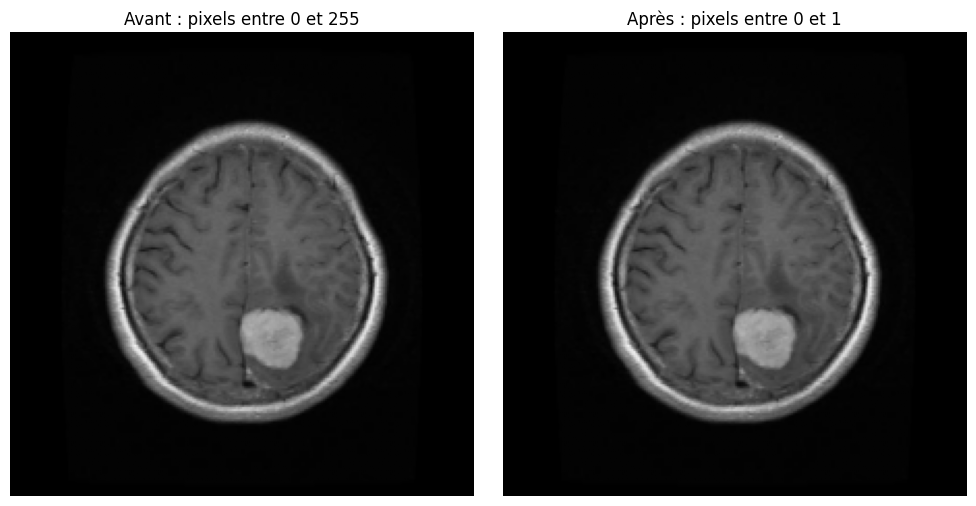

In [7]:
image_before = X_resized[0]
image_after = image_before.astype(np.float32) / 255.0

print(f"Avant : {image_before.dtype}, plage [{image_before.min()}, {image_before.max()}]")
print(f"Après : {image_after.dtype}, plage [{image_after.min():.3f}, {image_after.max():.3f}]")
print("Pixel [0, 0] :", image_before[0, 0, 0], "→", image_after[0, 0, 0])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_before[..., 0], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Avant : pixels entre 0 et 255")
axes[1].imshow(image_after[..., 0], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Après : pixels entre 0 et 1")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


Convertir les listes d'images et d'étiquettes en ```tableaux NumPy``` pour les rendre exploitables par le modèle.

In [8]:
encoder = LabelEncoder()

y = encoder.fit_transform(y)

Créer des datasets `tf.data` réutilisables. Les images sont en niveaux de gris `(224, 224, 1)` ; le cache précède le mélange et l'augmentation, afin que seules les données d'entraînement soient transformées à chaque passage.

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.03, fill_mode="constant", fill_value=0.0, seed=SEED
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.05, 0.05),
        width_factor=(-0.05, 0.05),
        fill_mode="constant", fill_value=0.0, seed=SEED + 1
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05, width_factor=0.05,
        fill_mode="constant", fill_value=0.0, seed=SEED + 2
    ),
], name="mri_augmentation")


def create_dataset(images, labels, training=False, cache_path=None):
    images = np.asarray(images)
    labels = np.asarray(labels)

    if images.ndim != 4 or images.shape[1:] != (224, 224, 1):
        raise ValueError(f"Expected grayscale images of shape (N, 224, 224, 1), got {images.shape}")
    if len(images) != len(labels):
        raise ValueError("Images and labels must have the same length")

    dataset = tf.data.Dataset.from_tensor_slices((images, labels))

    if cache_path is None:
        dataset = dataset.cache()
    else:
        dataset = dataset.cache(str(cache_path))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(images),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.map(
        lambda batch_images, batch_labels: (
            tf.cast(batch_images, tf.float32) / 255.0,
            batch_labels
        ),
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.map(
            lambda batch_images, batch_labels: (
                data_augmentation(batch_images, training=True),
                batch_labels
            ),
            num_parallel_calls=AUTOTUNE
        )

    return dataset.prefetch(AUTOTUNE)


2026-10-16 14:51:52.571262: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Afficher la répartition des images par classe (ex. ```diagramme avec Matplotlib ou Seaborn```) et un échantillon d'images pour chaque classe.

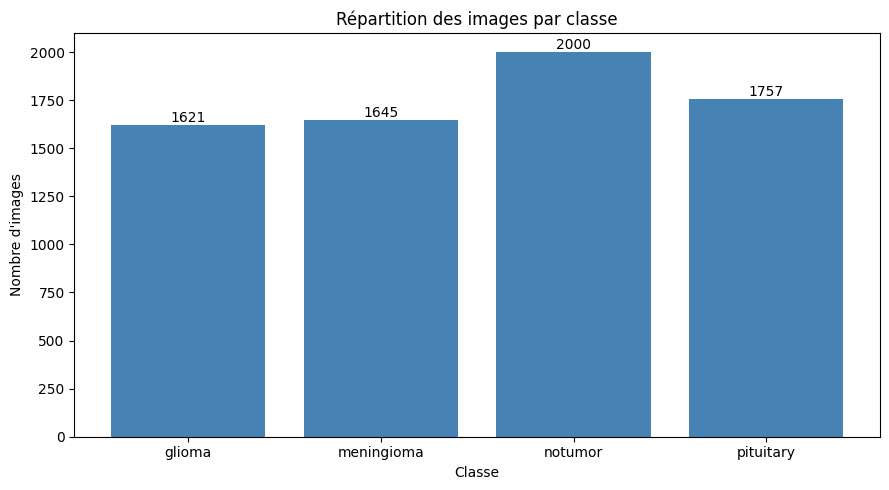

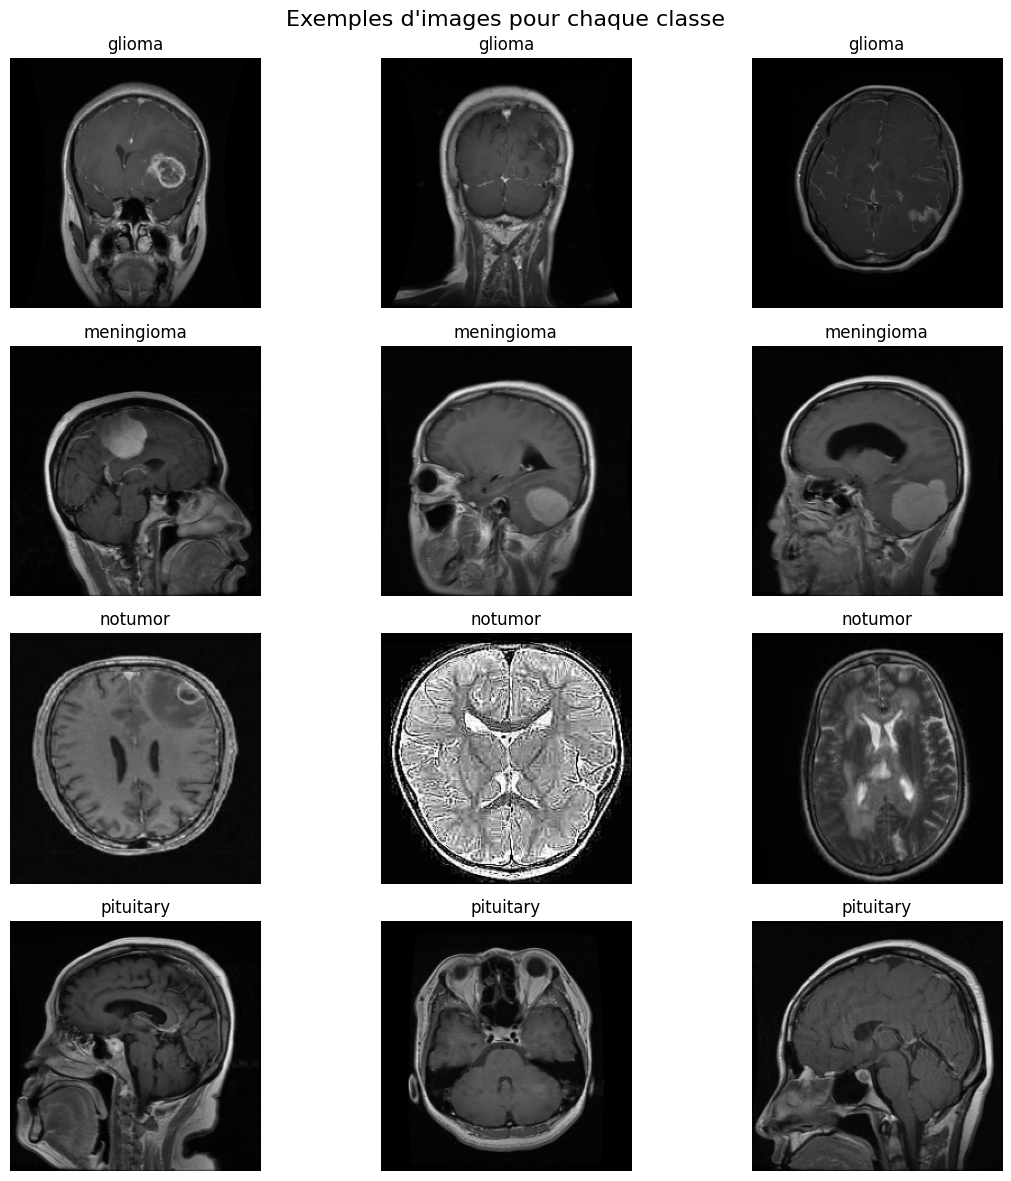

In [10]:
class_names = encoder.classes_
class_counts = np.bincount(y, minlength=len(class_names))

plt.figure(figsize=(9, 5))
bars = plt.bar(class_names, class_counts, color="steelblue")

for bar, count in zip(bars, class_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.title("Répartition des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.tight_layout()
plt.show()


samples_per_class = 3
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(
    len(class_names),
    samples_per_class,
    figsize=(12, 12)
)

for class_index, class_name in enumerate(class_names):
    indices = np.flatnonzero(y == class_index)
    selected = rng.choice(
        indices,
        size=min(samples_per_class, len(indices)),
        replace=False
    )

    for column in range(samples_per_class):
        ax = axes[class_index, column]
        ax.axis("off")

        if column < len(selected):
            image = X_resized[selected[column]]
            ax.imshow(image[..., 0], cmap="gray", vmin=0, vmax=255)
            ax.set_title(class_name)

plt.suptitle("Exemples d'images pour chaque classe", fontsize=16)
plt.tight_layout()
plt.show()

Vérifier l'équilibre entre les classes et appliquer un rééquilibrage si nécessaire (ex. ```class_weight``` ou augmentation ciblée).

In [11]:
class_names = encoder.classes_
class_counts = np.bincount(y, minlength=len(class_names))

for name, count in zip(class_names, class_counts):
    print(f"{name}: {count} images")

if np.any(class_counts == 0):
    print("Attention : au moins une classe ne contient aucune image.")
else:
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Rapport classe majoritaire / minoritaire : {imbalance_ratio:.2f}")

    if imbalance_ratio >= 1.5:
        print("Déséquilibre notable : class_weight est conseillé.")
    else:
        print("Répartition assez proche : rééquilibrage probablement inutile.")

glioma: 1621 images
meningioma: 1645 images
notumor: 2000 images
pituitary: 1757 images
Rapport classe majoritaire / minoritaire : 1.23
Répartition assez proche : rééquilibrage probablement inutile.


In [12]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_resized,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print(f"Entraînement : {len(X_train)} images")
print(f"Validation   : {len(X_val)} images")
print(f"Test         : {len(X_test)} images")

Entraînement : 4916 images
Validation   : 1053 images
Test         : 1054 images


Calculer un éventuel rééquilibrage **sur l'entraînement uniquement**. Le rapport 1,5 est un repère pratique ; si les classes sont proches, `class_weights=None`.


In [13]:
train_counts = np.bincount(y_train, minlength=len(encoder.classes_))

train_imbalance_ratio = train_counts.max() / train_counts.min()
if train_imbalance_ratio >= 1.5:
    classes = np.arange(len(encoder.classes_))
    weights = compute_class_weight(
        class_weight="balanced", classes=classes, y=y_train
    )
    class_weights = {
        int(class_id): float(weight)
        for class_id, weight in zip(classes, weights)
    }
else:
    class_weights = None

print("Training class counts:", dict(zip(encoder.classes_, train_counts)))
print(f"Training imbalance ratio: {train_imbalance_ratio:.2f}")
print("class_weights:", class_weights)


Training class counts: {np.str_('glioma'): np.int64(1135), np.str_('meningioma'): np.int64(1151), np.str_('notumor'): np.int64(1400), np.str_('pituitary'): np.int64(1230)}
Training imbalance ratio: 1.23
class_weights: None


In [ ]:
num_classes = len(encoder.classes_)

y_train_onehot = tf.keras.utils.to_categorical(y_train, num_classes).astype(np.float32)
y_val_onehot = tf.keras.utils.to_categorical(y_val, num_classes).astype(np.float32)
y_test_onehot = tf.keras.utils.to_categorical(y_test, num_classes).astype(np.float32)

train_ds = create_dataset(X_train, y_train_onehot, training=True)
val_ds = create_dataset(X_val, y_val_onehot, training=False)
test_ds = create_dataset(X_test, y_test_onehot, training=False)

print("Training images:", train_ds.element_spec[0])
print("Training labels:", train_ds.element_spec[1])


In [ ]:
# Check the accelerator before a long training run.
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow GPUs:", gpus)
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
if not gpus:
    print("No GPU detected. In Kaggle, enable a GPU accelerator and restart the session.")


Training

In [15]:

def build_cnn(input_shape=(224, 224, 1), num_classes=4):

    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu"
    )(inputs)

    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(
        64, (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(
        128, (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation="relu")(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return Model(inputs=inputs, outputs=outputs)


In [16]:
model = build_cnn(
    input_shape=(224, 224, 1),
    num_classes=len(encoder.classes_)
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,700 (428.52 KB)

 Trainable params: 109,700 (428.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# A smaller learning rate is a controlled response to unstable validation loss.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


**Premier essai enregistré :** 154 batches par époque, environ 256 à 261 s par époque. L'accuracy d'entraînement était proche de 0,75 ; l'accuracy de validation a varié de 0,666 à 0,542 puis 0,566, avec une perte de validation croissante. Cette variation motive un essai avec un taux d'apprentissage plus faible. La lenteur doit être vérifiée avec le diagnostic GPU ci-dessus ; ces journaux ne suffisent pas à eux seuls à identifier la cause.


In [ ]:
import time

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2,
        min_lr=1e-5, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4,
        restore_best_weights=True, verbose=1
    ),
]

start_time = time.perf_counter()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=2,
)
print(f"Training time: {(time.perf_counter() - start_time) / 60:.1f} minutes")


Inspecter la précision par classe sur la **validation** après l'entraînement. Garder `test_ds` pour l'évaluation finale.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

val_true = np.concatenate([
    np.argmax(batch_labels.numpy(), axis=1)
    for _, batch_labels in val_ds
])
val_scores = model.predict(val_ds, verbose=0)
val_pred = np.argmax(val_scores, axis=1)

print(classification_report(
    val_true, val_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))
print("Confusion matrix:\n", confusion_matrix(val_true, val_pred))
